# 4. Stage 3: Target, detection and estimation

## The bi-static radar equation (Willis, *Bistatic Radar*)

$$P_r = \frac{P_t G_t G_r \lambda^2 \sigma_b}{(4\pi)^3 R_t^2 R_r^2 L}$$

For a given SNR, the maximum range product $R_tR_r$ is a constant, so detection contours are **Cassini ovals** around the two sites.

## Waveforms

Each waveform supplies its bandwidth, duty cycle, PAPR and leakage of the direct signal into the target's range-Doppler cell.

| Waveform | Key effect |
|---|---|
| Pulsed LFM | Direct path is separated in time; eclipsing; blind Doppler |
| Random phase code | Floor near $-10\log_{10}(BT)$ in every cell |
| Zadoff-Chu | Zero periodic autocorrelation, but ambiguous at the code period and Doppler sensitive |
| FM | Bandwidth depends on programme content |
| DAB, DVB-T | OFDM: high PAPR; ambiguities from guard intervals and pilots |

The model values are checked against generated signals below.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.config import WaveformConfig
from bistatic_lb.waveforms import WAVEFORMS, make_waveform

rng = np.random.default_rng(1)
print(f"{'Waveform':28s}{'B (MHz)':>9s}{'BT':>12s}{'Gain dB':>9s}{'PAPR model':>12s}{'PAPR measured':>15s}")
for kind in WAVEFORMS:
    wf = make_waveform(WaveformConfig(kind=kind, cpi_s=0.2, bandwidth_hz=2e6, pulse_width_s=500e-6 if kind == "zadoff_chu" else 100e-6, prf_hz=2000.0))
    fs = max(4 * wf.bandwidth_hz, 1e6)
    x = wf.generate(fs, 0.2, rng)
    active = np.abs(x) ** 2
    active = active[active > 0]
    measured = 10 * np.log10(np.quantile(active, 1 - 1.3e-5) / active.mean())
    print(f"{wf.name:28s}{wf.bandwidth_hz/1e6:9.3f}{wf.time_bandwidth:12.3g}{wf.processing_gain_db:9.1f}{wf.papr_db:12.1f}{measured:15.1f}")


Waveform                      B (MHz)          BT  Gain dB  PAPR model  PAPR measured
Pulsed LFM                      2.000       8e+04     47.7         0.0            0.0
Phase-coded (noise-like)        2.000       4e+05     54.7         3.0            0.0
Zadoff-Chu                      2.000       4e+05     54.7         0.0            0.0
FM broadcast                    0.050       1e+04     38.7         0.0            0.0


DAB (Mode I)                    1.536    3.03e+05     53.5        10.5           10.3


DVB-T (8k)                      7.610    1.52e+06     60.5        10.5           10.5


Random phase code reads 0 dB as generated because it has rectangular chips. A band-limited transmitter raises this, so the model uses 3 dB.

## Target fluctuation

The noise-normalized detector statistic is $Y = \sum_{i=1}^n |s_i + w_i|^2$. Noise alone makes $Y$ Gamma$(n,1)$, so the threshold is exact for any $P_{fa}$. $Y$ depends on the signal only through total power $X=\sum|s_i|^2$, which gives one simple form for all models:

$$P_d = E_X\left[Q_n\left(\sqrt{2X},\sqrt{2T}\right)\right]$$

| Model | Distribution of $X$ |
|---|---|
| Swerling 0 | Fixed |
| Swerling 1, 3 (scan-to-scan) | Chi-square order 1, 2, one draw across the looks |
| Swerling 2, 4 (pulse-to-pulse) | Chi-square order $n$, $2n$ |
| Chi-square, any $m$ (Weinstock) | Order $m$, one draw |
| Rician | Dominant plus diffuse scatterer |

## Check: analytic against Monte Carlo and closed forms

In [2]:
from bistatic_lb.target.detection import FLUCTUATION_MODELS, Fluctuation, detection_probability, required_snr_db, albersheim_snr_db, shnidman_snr_db
from bistatic_lb.target.montecarlo import detection_monte_carlo

models = list(FLUCTUATION_MODELS.values()) + [Fluctuation("Chi-square, m=1.5", "scan", 1.5), Fluctuation("Rician, K=6 dB", "rician", rician_k=4.0)]
print(f"{'Model':24s}{'n':>3s}{'Analytic':>10s}{'Simulated':>11s}")
for model in models:
    for n in (1, 4):
        a = detection_probability(10**1.2, 1e-2, n, model)
        m, _ = detection_monte_carlo(12.0, 1e-2, n, model, 200_000)
        print(f"{model.name:24s}{n:3d}{a:10.4f}{m:11.4f}")

print()
print("Required SNR for Pd 0.9, Pfa 1e-6, one look:")
print(f"  Swerling 0: exact {required_snr_db(.9,1e-6,1,FLUCTUATION_MODELS['swerling0']):.2f} dB, Albersheim {albersheim_snr_db(.9,1e-6,1):.2f} dB, Shnidman {shnidman_snr_db(.9,1e-6,1,0):.2f} dB")
print(f"  Swerling 1: exact {required_snr_db(.9,1e-6,1,FLUCTUATION_MODELS['swerling1']):.2f} dB, Shnidman {shnidman_snr_db(.9,1e-6,1,1):.2f} dB")


Model                     n  Analytic  Simulated
Swerling 0 (steady)       1    0.9967     0.9969
Swerling 0 (steady)       4    1.0000     1.0000
Swerling 1                1    0.7608     0.7589


Swerling 1                4    0.8966     0.8967
Swerling 2                1    0.7608     0.7589


Swerling 2                4    0.9967     0.9969
Swerling 3                1    0.8704     0.8687


Swerling 3                4    0.9737     0.9739
Swerling 4                1    0.8704     0.8687


Swerling 4                4    0.9999     0.9998
Chi-square, m=1.5         1    0.8299     0.8295


Chi-square, m=1.5         4    0.9500     0.9505
Rician, K=6 dB            1    0.8950     0.8951


Rician, K=6 dB            4    0.9779     0.9781

Required SNR for Pd 0.9, Pfa 1e-6, one look:
  Swerling 0: exact 13.18 dB, Albersheim 13.11 dB, Shnidman 13.12 dB
  Swerling 1: exact 21.14 dB, Shnidman 21.35 dB


## False-alarm probability and CFAR

$P_{fa}$ is set from a false-alarm rate across all search cells: $P_{fa} = \text{FAR}\cdot T / N_{cells}$, with cells across range, Doppler and beams. CA-CFAR adds a loss, taken from the exact Swerling 1 result.

## This design

Rt 26.5 km, Rr 30.0 km, beta 40.9 deg
Received -134.8 dBm; in the target's cell: noise -163.1, direct residual -173.1, clutter -222.4 dBm
SNR 28.3 dB, SINR 27.9 dB, Pd 0.946, Pfa 6.45e-11, margin +2.8 dB


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


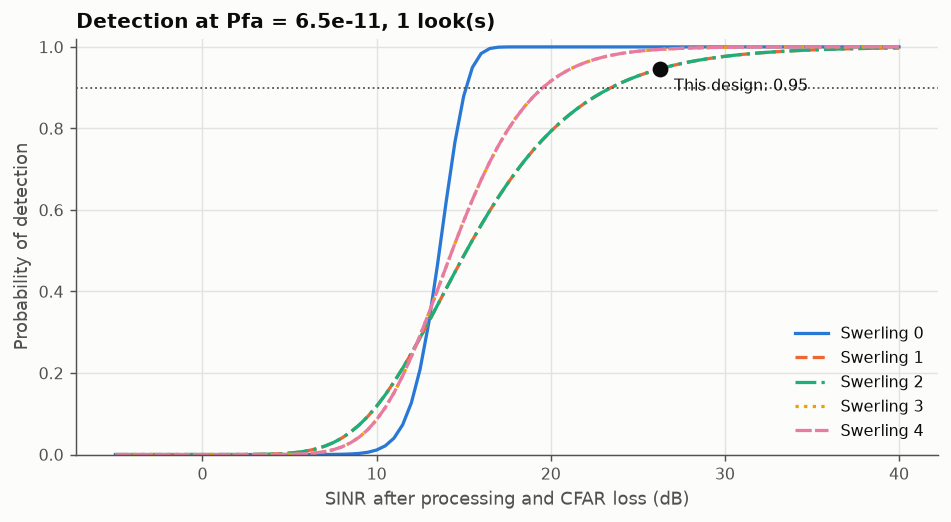

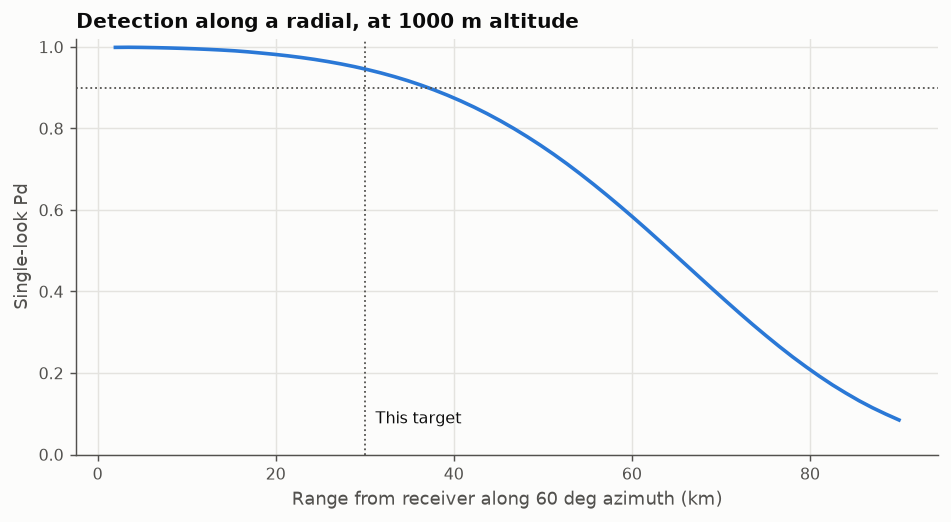

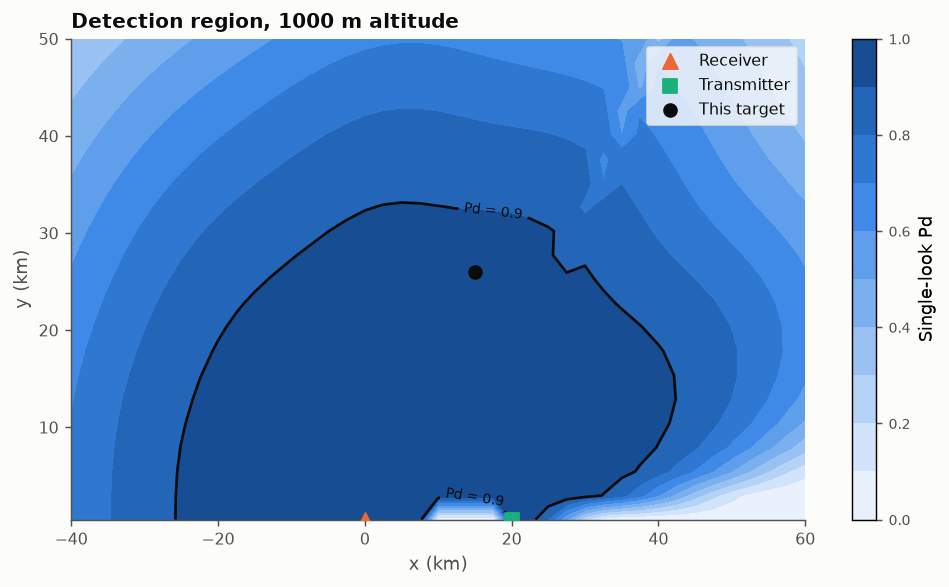

In [3]:
s = Scenario.from_yaml(Path("../scenarios/dvbt_uhf.yaml" if Path.cwd().name == "notebooks" else "scenarios/dvbt_uhf.yaml"))
r = run_link_budget(s)
l, d = r.link, r.detection
print(f"Rt {l.geometry.range_tx_m/1e3:.1f} km, Rr {l.geometry.range_rx_m/1e3:.1f} km, beta {np.rad2deg(l.geometry.bistatic_angle_rad):.1f} deg")
print(f"Received {l.received_dbm:.1f} dBm; in the target's cell: noise {l.noise_cell_dbm:.1f}, direct residual {l.direct_cell_dbm:.1f}, clutter {l.clutter_cell_dbm:.1f} dBm")
print(f"SNR {l.snr_db:.1f} dB, SINR {l.sinr_db:.1f} dB, Pd {d.pd:.3f}, Pfa {d.pfa:.2e}, margin {d.margin_db:+.1f} dB")
plots.pd_vs_snr(r); plots.pd_vs_range(r); plots.detection_map(r); plt.show()


Note the shape: the Cassini-oval form, and the gap along the baseline, where the null on the transmitter and the poor forward-scatter geometry remove coverage.

## Estimation

Cramer-Rao bounds, with SNR $= E/N_0$:

$$\sigma_\tau = \frac{1}{2\pi B_{rms}\sqrt{2\,\mathrm{SNR}}},\qquad \sigma_f = \frac{1}{2\pi T_{rms}\sqrt{2\,\mathrm{SNR}}}$$

A flat spectrum has $B_{rms}=B/\sqrt{12}$, and a uniform time window has $T_{rms}=T/\sqrt{12}$.

**The bound holds only above a threshold SNR.** Below it, noise peaks elsewhere in the search space win, and errors become large outliers. A union bound on $M$ independent cells gives the estimate $\mathrm{SNR}_{th} \approx 2\ln(M/2P_e)$.

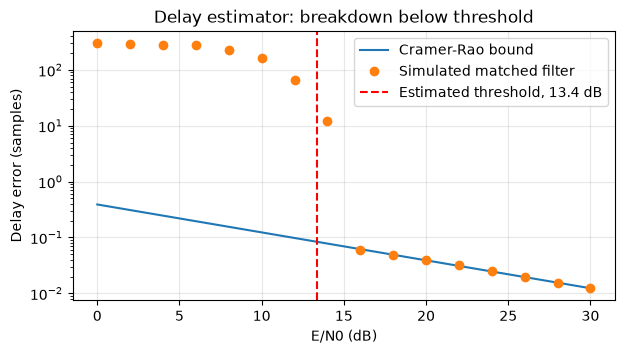

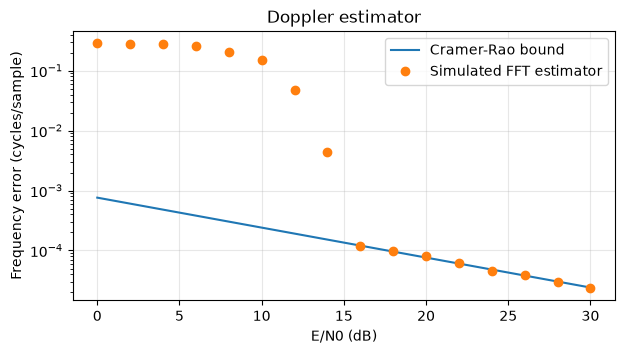

In [4]:
from bistatic_lb.target.estimation import delay_crlb_s, doppler_crlb_hz, outlier_threshold_snr_db
from bistatic_lb.target.montecarlo import delay_estimator_rmse, doppler_estimator_rmse

snr = np.arange(0.0, 31.0, 2.0)
measured = delay_estimator_rmse(snr, n_samples=1024, trials=400)
bound = delay_crlb_s(10**(snr/10), 1/np.sqrt(12))
threshold = outlier_threshold_snr_db(1024)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(snr, bound, label="Cramer-Rao bound"); ax.semilogy(snr, measured, "o", label="Simulated matched filter")
ax.axvline(threshold, ls="--", color="r", label=f"Estimated threshold, {threshold:.1f} dB")
ax.set(xlabel="E/N0 (dB)", ylabel="Delay error (samples)", title="Delay estimator: breakdown below threshold"); ax.grid(alpha=0.3); ax.legend(); plt.show()

measured_f = doppler_estimator_rmse(snr, n_samples=512, trials=400)
bound_f = doppler_crlb_hz(10**(snr/10), 512/np.sqrt(12))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(snr, bound_f, label="Cramer-Rao bound"); ax.semilogy(snr, measured_f, "o", label="Simulated FFT estimator")
ax.set(xlabel="E/N0 (dB)", ylabel="Frequency error (cycles/sample)", title="Doppler estimator"); ax.grid(alpha=0.3); ax.legend(); plt.show()


In [5]:
e = r.estimation
print(f"Bi-static range sigma {e.sigma_bistatic_range_m:.2f} m (resolution {e.range_resolution_m:.0f} m)")
print(f"Doppler sigma {e.sigma_doppler_hz:.3f} Hz, range-rate sigma {e.sigma_range_rate_m_s:.4f} m/s")
print(f"Azimuth sigma {e.sigma_azimuth_deg:.2f} deg")
print(f"Position rms {e.position_rms_m:.0f} m, from range and azimuth through the geometry")
print(f"RCS error {e.rcs_measurement_std_db:.2f} dB from noise, {e.rcs_total_std_db:.2f} dB with fluctuation")


Bi-static range sigma 0.62 m (resolution 21 m)
Doppler sigma 0.078 Hz, range-rate sigma 0.0391 m/s
Azimuth sigma 0.36 deg
Position rms 200 m, from range and azimuth through the geometry
RCS error 0.25 dB from noise, 4.35 dB with fluctuation


Position is limited by azimuth, not by range. Cross-range error is roughly $R_r\sigma_\theta$, which is much larger than the range error. That's why adding array aperture usually improves position more than adding bandwidth does.

### Trade-off: aperture against bandwidth

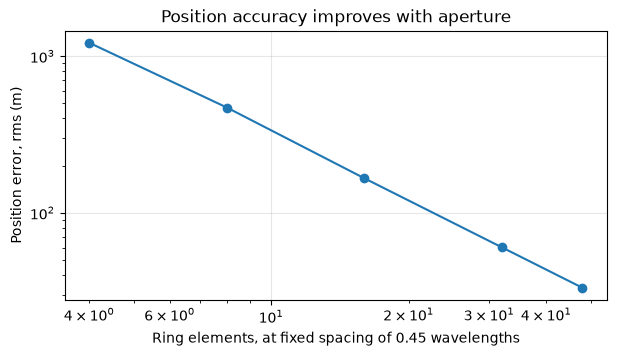

In [6]:
from bistatic_lb.sweeps import sweep
fig, ax = plt.subplots(figsize=(7, 3.5))
n = np.array([4, 8, 16, 32, 48])
results = []
for count in n:
    t = s.with_value("array.n_circular", int(count)).with_value("array.radius_wavelengths", float(0.45/(2*np.sin(np.pi/count))))
    results.append(run_link_budget(t).estimation.position_rms_m)
ax.loglog(n, results, marker="o")
ax.set(xlabel="Ring elements, at fixed spacing of 0.45 wavelengths", ylabel="Position error, rms (m)", title="Position accuracy improves with aperture"); ax.grid(alpha=0.3); plt.show()
